# mogul: results

What the strategy does, from the derived daily series in `data/`; no market data is required. Every series is the
daily-marked P&L of a book that sells a delta-hedged VIX option structure every trading day at 100 $ of vega per entry.
The full specification, engine, decision log and the fourteen research notebooks live in the private repository.

Windows:
- **dev:** 2015–2023, where every design choice was made.
- **holdout:** 2024-01 → 2026-09, read once.
- **backcast:** 2008-07 → 2013, a second vendor, read once.

In [1]:
import datetime as dt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

DATA = Path("data")
INK, BG, BG1, GRID = "#d3c6b0", "#130e0a", "#201812", "#43352a"
COL = {"C4 call-heavy + gate": "#a8d88a", "C4 call-heavy + gate + vol-of-vol sizing": "#c4dca8", "C4 call-heavy": "#e59a5b",
       "C1 strangle (frozen)": "#a99a85", "C0 control (frozen)": "#7a6852"}
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG1, "savefig.facecolor": BG, "text.color": INK, "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK, "axes.edgecolor": GRID, "grid.color": GRID, "axes.grid": True,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.facecolor": BG1, "legend.edgecolor": GRID, "font.size": 10})
daily = pl.read_parquet(DATA / "book_daily.parquet")
back = pl.read_parquet(DATA / "backcast_daily.parquet")
ent = pl.read_parquet(DATA / "entries_by_vix_dev.parquet")
cards = pl.read_parquet(DATA / "holdout_cards.parquet")

def sharpe(x):
    x = np.asarray(x, float)
    return float(x.mean() / x.std(ddof=1) * np.sqrt(252))

def card(x):
    x = np.asarray(x, float); cum = np.cumsum(x); sd = x.std(ddof=1) * np.sqrt(252)
    return {"sharpe": sharpe(x), "annual_pnl": x.sum() / (len(x) / 252), "max_dd": (cum - np.maximum.accumulate(cum)).min(), "dd_in_annual_vols": -(cum - np.maximum.accumulate(cum)).min() / sd}

## 1. Performance, 2015 → 2026

**How to read.** Cumulative P&L of the carried book (C4 call-heavy + gate) against the frozen strangle (C1) and the
ungated C4. The shaded area is the holdout, read once. The table gives each book's Sharpe and drawdown per window.

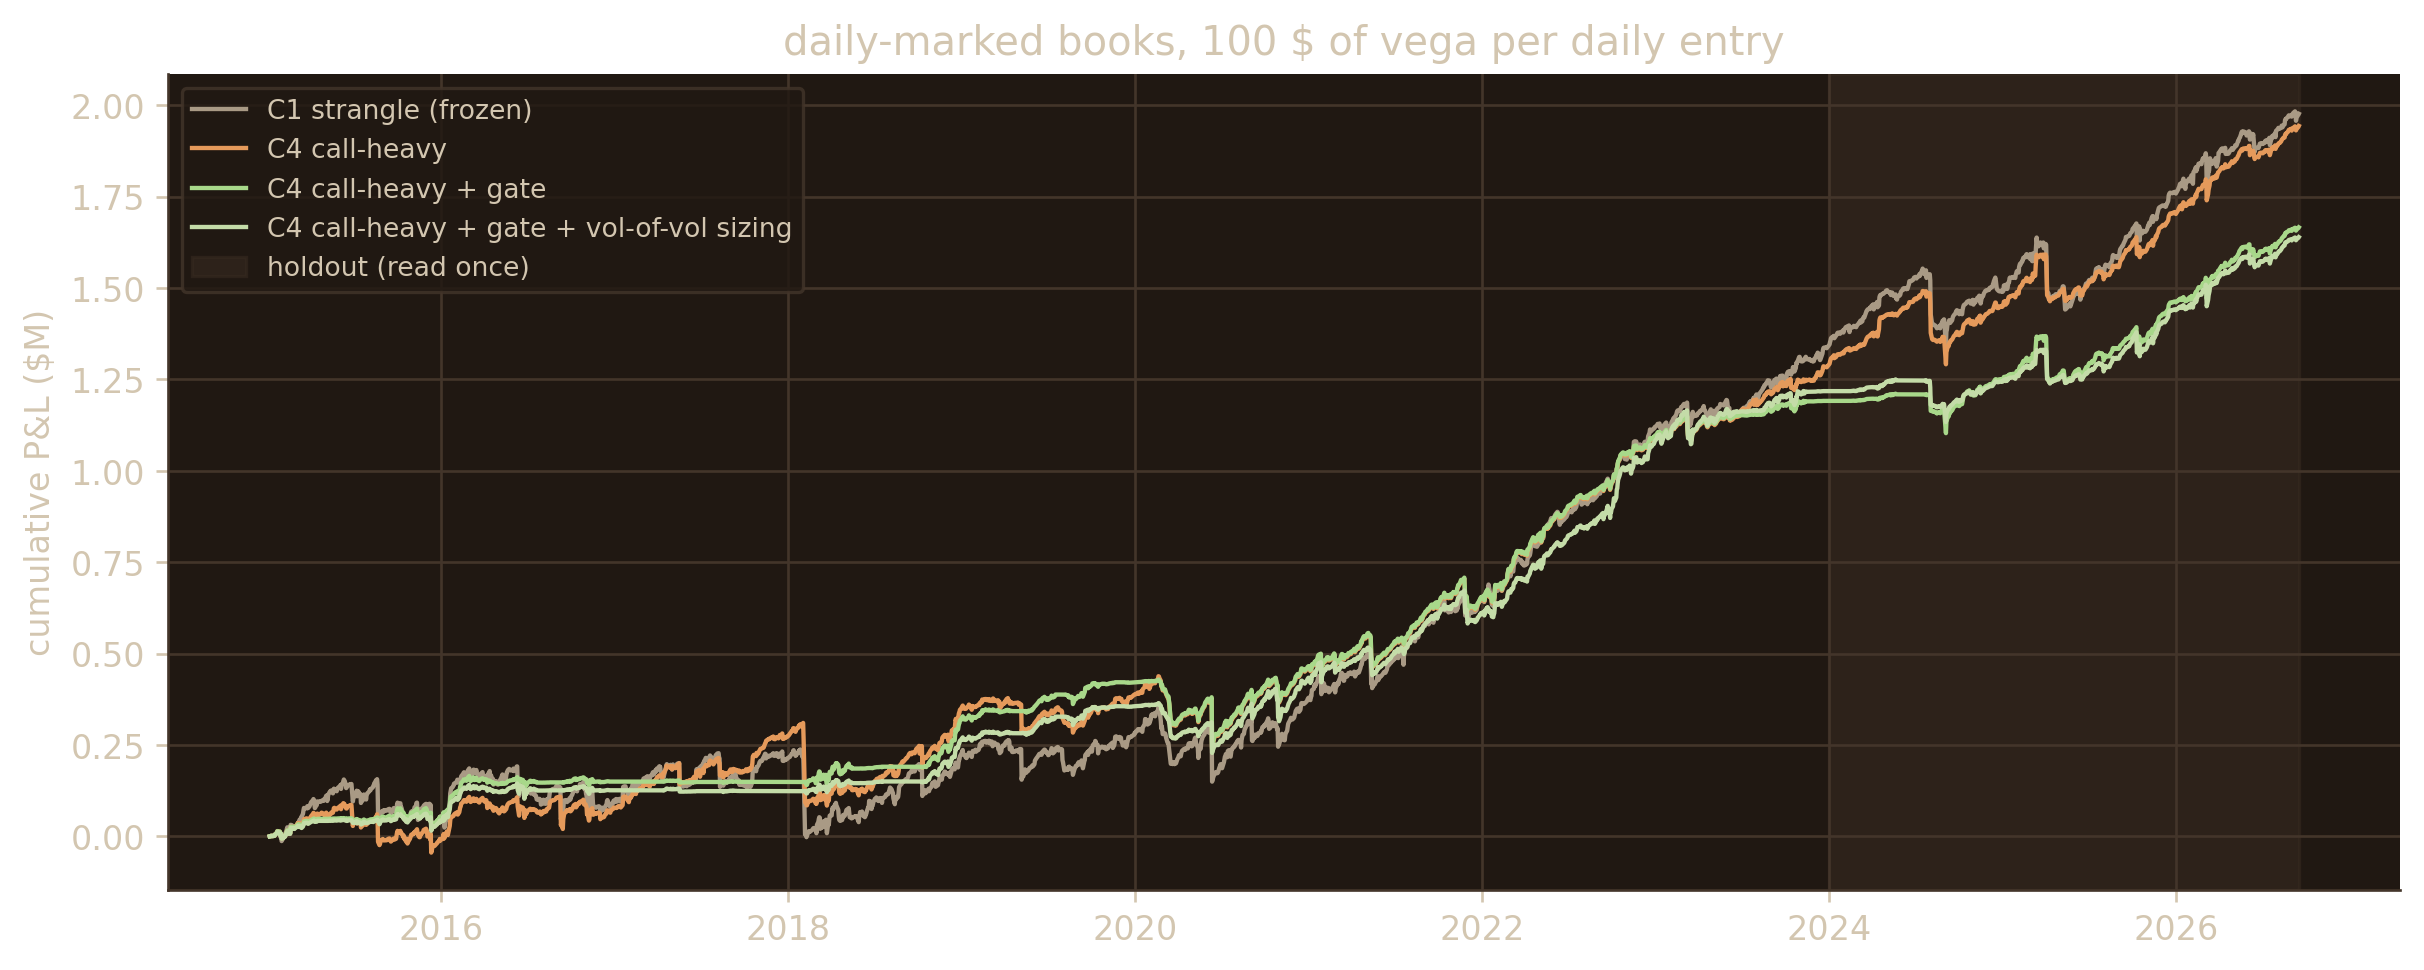

shape: (8, 6)
┌────────────────────────┬─────────┬──────────┬───────────────┬────────────────┬───────────────────┐
│ book                   ┆ window  ┆ sharpe   ┆ annual_pnl    ┆ max_dd         ┆ dd_in_annual_vols │
│ ---                    ┆ ---     ┆ ---      ┆ ---           ┆ ---            ┆ ---               │
│ str                    ┆ str     ┆ f64      ┆ f64           ┆ f64            ┆ f64               │
╞════════════════════════╪═════════╪══════════╪═══════════════╪════════════════╪═══════════════════╡
│ C1 strangle (frozen)   ┆ dev     ┆ 0.92479  ┆ 149160.528937 ┆ -240046.247911 ┆ 1.488278          │
│ C1 strangle (frozen)   ┆ holdout ┆ 1.483047 ┆ 236899.261776 ┆ -203566.707513 ┆ 1.274377          │
│ C4 call-heavy          ┆ dev     ┆ 1.073534 ┆ 143303.726363 ┆ -226147.343908 ┆ 1.694143          │
│ C4 call-heavy          ┆ holdout ┆ 1.920235 ┆ 244095.201478 ┆ -200447.712059 ┆ 1.576872          │
│ C4 call-heavy + gate   ┆ dev     ┆ 1.581577 ┆ 156691.226924 ┆ -185495.86878

In [2]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for b in ["C1 strangle (frozen)", "C4 call-heavy", "C4 call-heavy + gate", "C4 call-heavy + gate + vol-of-vol sizing"]:
    s = daily.filter(pl.col("book") == b).sort("date")
    ax.plot(s["date"], np.cumsum(s["pnl"].to_numpy()) / 1e6, lw=1.3, color=COL[b], label=b)
ax.axvspan(dt.date(2024, 1, 1), daily["date"].max(), color="#362a20", alpha=0.6, label="holdout (read once)")
ax.set_ylabel("cumulative P&L ($M)"); ax.legend(fontsize=8, loc="upper left"); ax.set_title("daily-marked books, 100 $ of vega per daily entry")
plt.show()
print(pl.DataFrame([{"book": b, "window": w, **card(daily.filter((pl.col("book") == b) & (pl.col("window") == w))["pnl"])}
                    for b in daily["book"].unique(maintain_order=True) for w in ("dev", "holdout")]))

**Conclusion.** Every book makes money in both windows. The gate (no new entries when VIX is low) lifts the dev
Sharpe and makes the dollar drawdown shallower (in units of the book's own vol it is a little deeper); on the holdout the ungated book did better, because 2024–26 had no low-VIX blow-up of
the Feb-2018 kind, the event the gate insures against.

## 2. Where the premium is paid: the VIX level

**How to read.** Every dev entry of the ungated call-heavy book, grouped by the previous day's VIX close: the mean P&L
per entry and its per-entry Sharpe (mean / sd).

shape: (5, 4)
┌────────┬─────────┬─────────────┬─────────────────┐
│ bucket ┆ entries ┆ mean_usd    ┆ per_entry_ratio │
│ ---    ┆ ---     ┆ ---         ┆ ---             │
│ enum   ┆ u32     ┆ f64         ┆ f64             │
╞════════╪═════════╪═════════════╪═════════════════╡
│ <15    ┆ 703     ┆ -9.346283   ┆ -0.002722       │
│ 15-20  ┆ 529     ┆ 936.309394  ┆ 0.48691         │
│ 20-25  ┆ 339     ┆ 1551.528247 ┆ 1.147163        │
│ 25-35  ┆ 233     ┆ 1453.217508 ┆ 0.710342        │
│ >35    ┆ 44      ┆ -537.017285 ┆ -0.10306        │
└────────┴─────────┴─────────────┴─────────────────┘


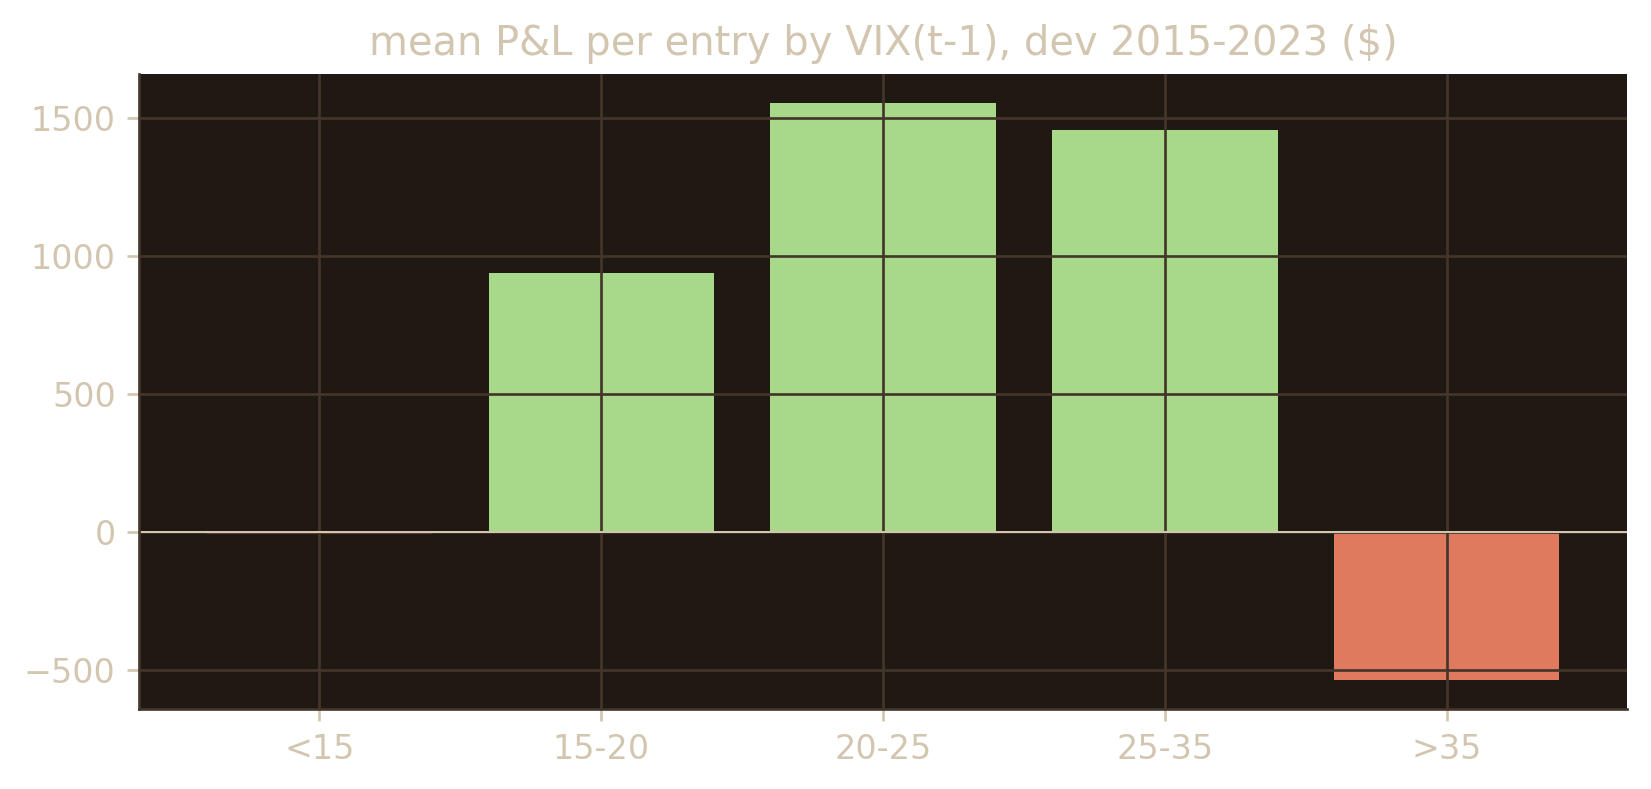

In [3]:
b = ent.with_columns(bucket=pl.col("VIX").cut([15, 20, 25, 35], labels=["<15", "15-20", "20-25", "25-35", ">35"], left_closed=True))
LABS = ["<15", "15-20", "20-25", "25-35", ">35"]
t = (b.group_by("bucket").agg(entries=pl.len(), mean_usd=pl.col("usd").mean(), per_entry_ratio=pl.col("usd").mean() / pl.col("usd").std())
     .with_columns(pl.col("bucket").cast(pl.Utf8).cast(pl.Enum(LABS))).sort("bucket"))
print(t)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(t["bucket"].cast(pl.Utf8), t["mean_usd"], color=["#e07a5f" if v < 0 else "#a8d88a" for v in t["mean_usd"]])
ax.axhline(0, color=INK, lw=0.6); ax.set_title("mean P&L per entry by VIX(t-1), dev 2015-2023 ($)"); plt.show()

**Conclusion.** The premium is a hump in the VIX level. Below 15 it is too thin to pay for the tail, and above 35 one
episode decides the sign. VIX level is the only market state that ordered the premium consistently; the volatility of
VIX, its term structure and the richness of VVIX did not.

## 3. The holdout: one registered look

**How to read.** Each candidate registered before the holdout was opened, with its dev Sharpe and its holdout Sharpe
(99% CI). C0 is an untuned control, C1 the frozen prior-selected strangle, C3–C6 later amendments (gated, capped,
weekly).

shape: (6, 6)
┌───────────┬────────────┬────────────────┬───────────┬──────────┬──────────┐
│ candidate ┆ dev_sharpe ┆ holdout_sharpe ┆ lo99      ┆ hi99     ┆ keep     │
│ ---       ┆ ---        ┆ ---            ┆ ---       ┆ ---      ┆ ---      │
│ str       ┆ f64        ┆ f64            ┆ f64       ┆ f64      ┆ f64      │
╞═══════════╪════════════╪════════════════╪═══════════╪══════════╪══════════╡
│ C0        ┆ 0.88       ┆ 0.617342       ┆ -1.110019 ┆ 3.859399 ┆ 0.701525 │
│ C1        ┆ 0.92       ┆ 1.48152        ┆ -0.286061 ┆ 3.587253 ┆ 1.610348 │
│ C3        ┆ 1.44       ┆ 1.220295       ┆ -0.382851 ┆ 3.175069 ┆ 0.847427 │
│ C4        ┆ 1.07       ┆ 1.911117       ┆ -0.075855 ┆ 4.667352 ┆ 1.78609  │
│ C5        ┆ 1.84       ┆ 1.158637       ┆ -0.825463 ┆ 4.318658 ┆ 0.629694 │
│ C6        ┆ 2.63       ┆ 1.134261       ┆ -0.623531 ┆ 3.568133 ┆ 0.431278 │
└───────────┴────────────┴────────────────┴───────────┴──────────┴──────────┘


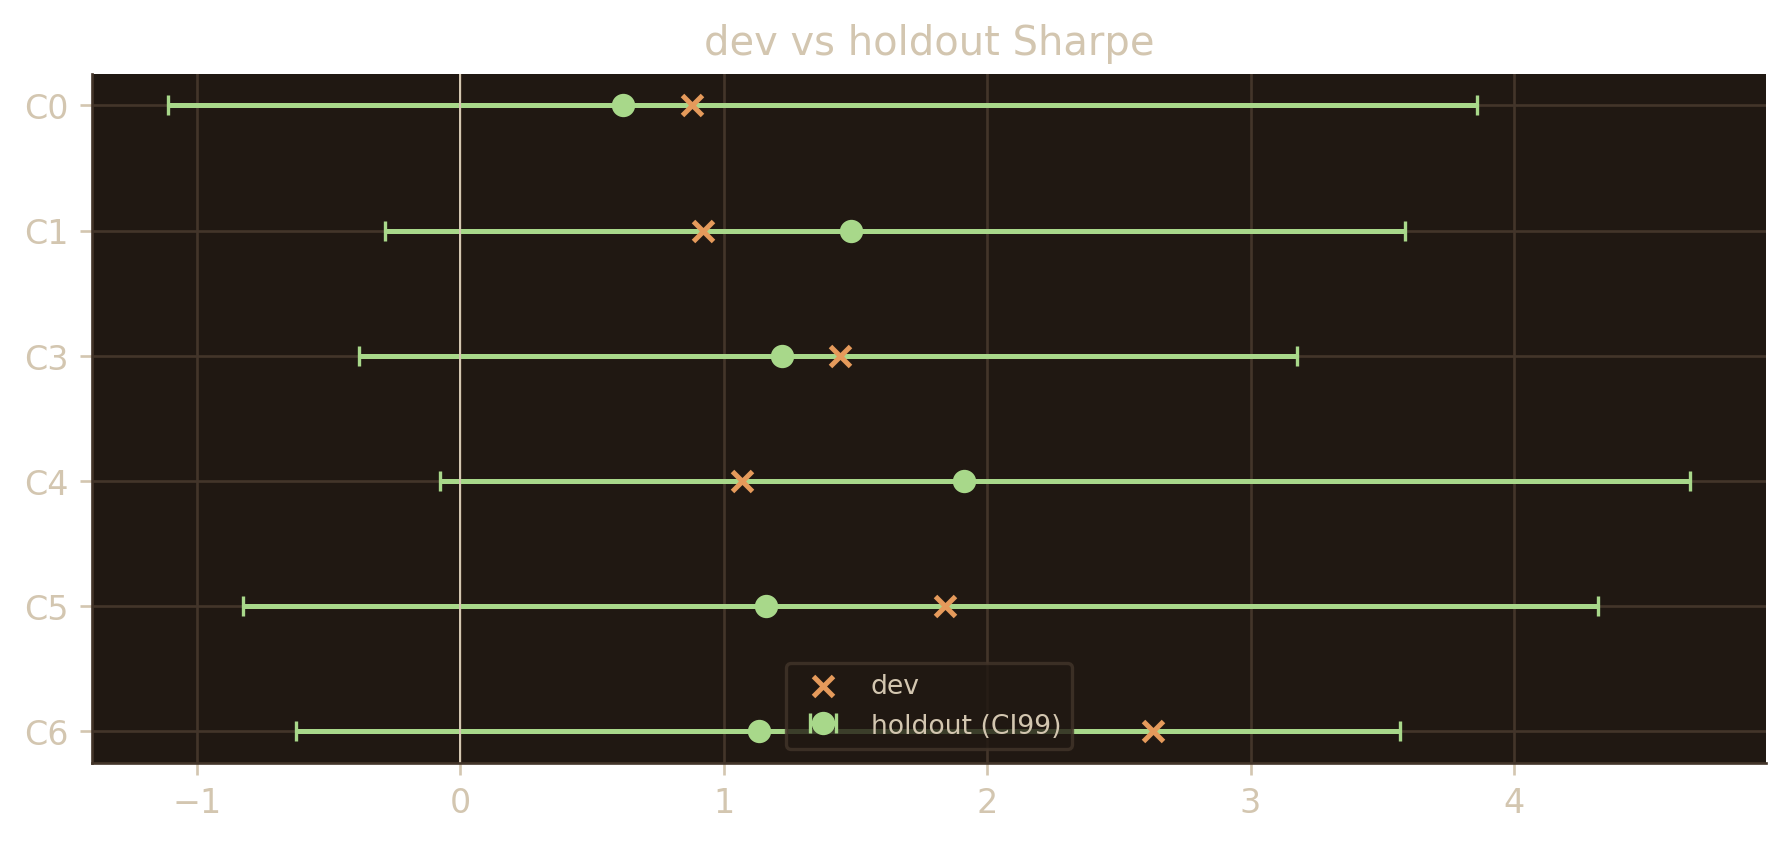

In [4]:
print(cards.with_columns(keep=pl.col("holdout_sharpe") / pl.col("dev_sharpe")))
fig, ax = plt.subplots(figsize=(9, 3.8)); y = np.arange(cards.height)[::-1]
ax.errorbar(cards["holdout_sharpe"], y, xerr=[cards["holdout_sharpe"] - cards["lo99"], cards["hi99"] - cards["holdout_sharpe"]], fmt="o", color="#a8d88a", capsize=3, label="holdout (CI99)")
ax.scatter(cards["dev_sharpe"], y, marker="x", color="#e59a5b", zorder=3, label="dev")
ax.set_yticks(y, cards["candidate"].to_list()); ax.axvline(0, color=INK, lw=0.6); ax.legend(fontsize=8); ax.set_title("dev vs holdout Sharpe"); plt.show()

**Conclusion.** The premium travelled: every candidate is positive and the frozen C1 passed its gates. The ranking
did not: the books built from dev regime cuts (C5, C6: gate + cap + tighter tenor) kept the least, the structure chosen
on economics (C4) kept the most. Structure travels; conditioning does not.

## 4. The backcast: 2008–2013, a second vendor, read once

**How to read.** The same books on OptionMetrics end-of-day data (the vendor was first checked against the main data
on 2015–2023). Then the carried book's Sharpe by era across all eighteen years.

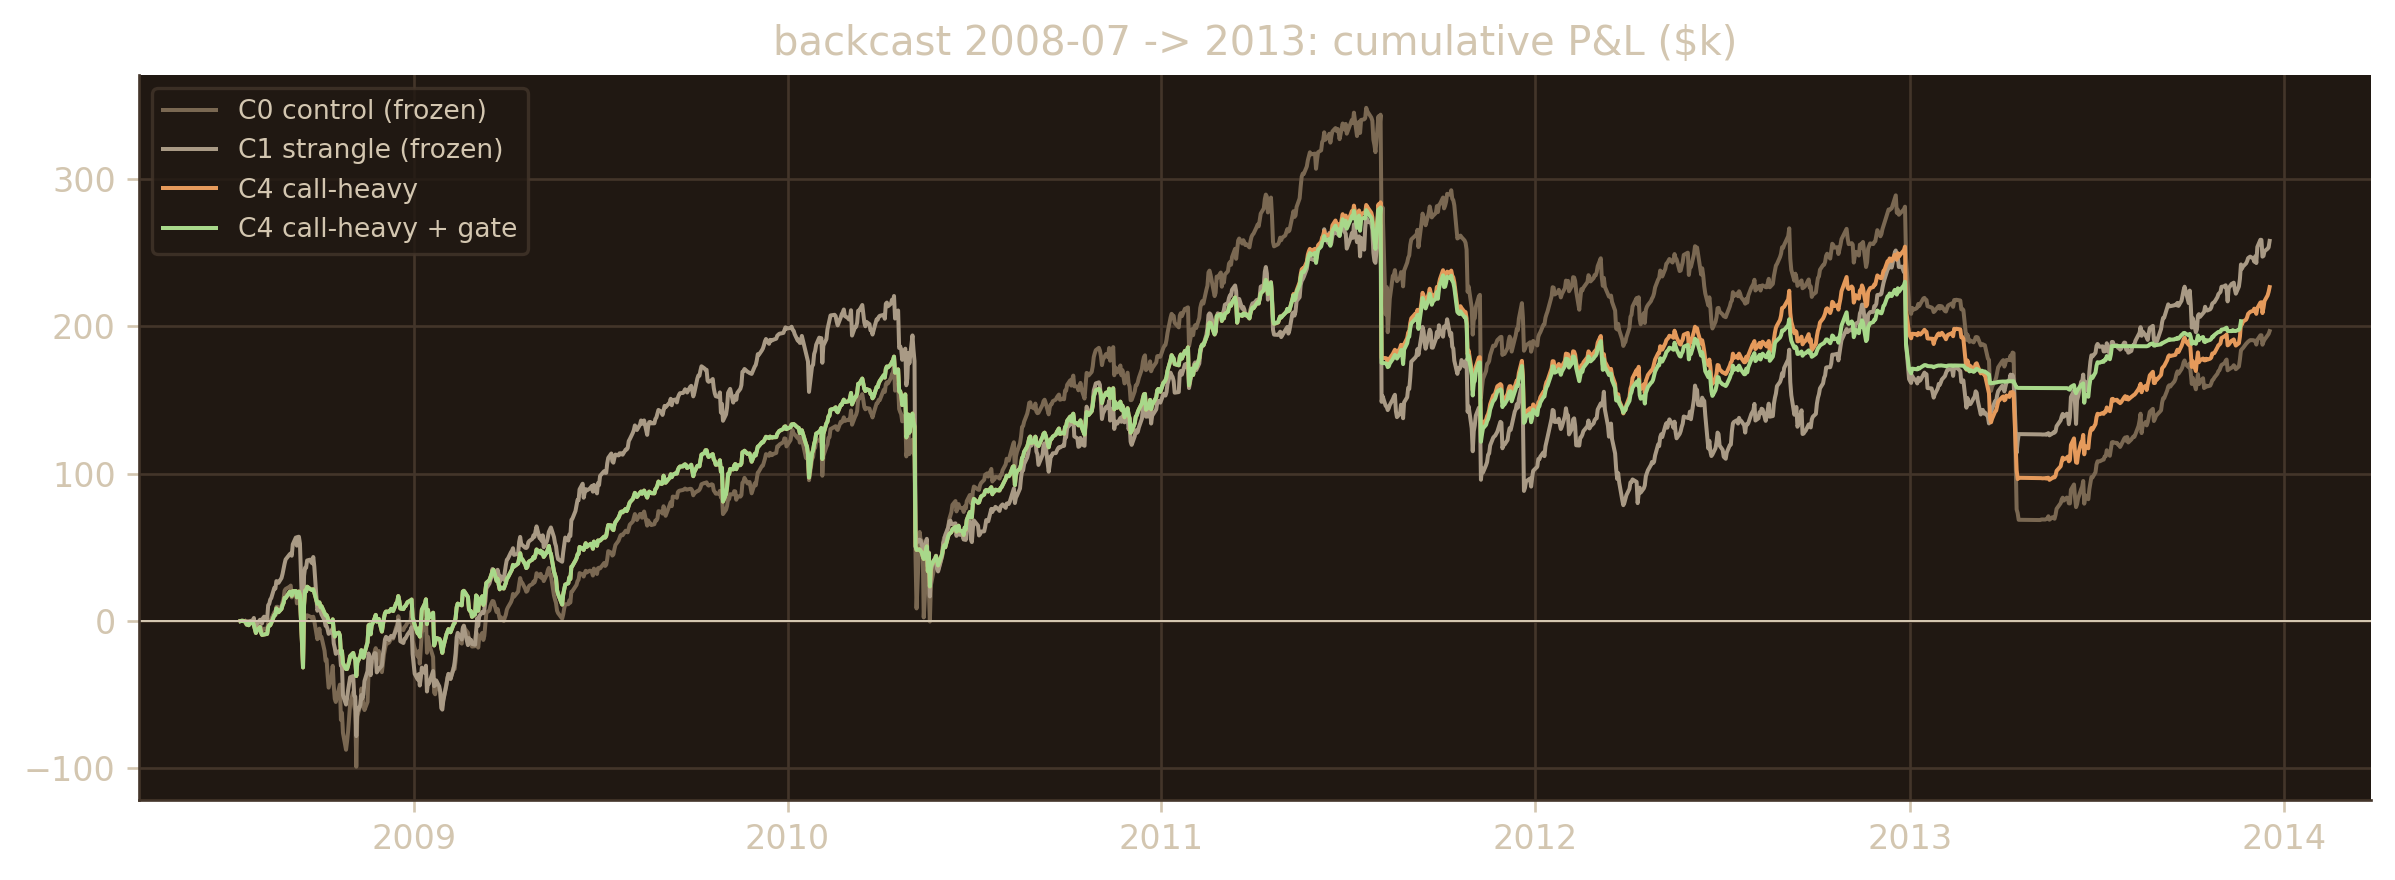

shape: (4, 3)
┌─────────┬──────────┬──────┐
│ era     ┆ sharpe   ┆ days │
│ ---     ┆ ---      ┆ ---  │
│ str     ┆ f64      ┆ i64  │
╞═════════╪══════════╪══════╡
│ 2008-13 ┆ 0.392168 ┆ 1289 │
│ 2015-19 ┆ 1.716069 ┆ 919  │
│ 2020-23 ┆ 1.605861 ┆ 997  │
│ 2024-26 ┆ 1.74269  ┆ 611  │
└─────────┴──────────┴──────┘


In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
for bk in back["book"].unique(maintain_order=True):
    s = back.filter(pl.col("book") == bk).sort("date"); ax.plot(s["date"], np.cumsum(s["pnl"].to_numpy()) / 1e3, lw=1.2, color=COL[bk], label=bk)
ax.axhline(0, color=INK, lw=0.6); ax.legend(fontsize=8); ax.set_title("backcast 2008-07 -> 2013: cumulative P&L ($k)"); plt.show()
c4g = "C4 call-heavy + gate"
eras = {"2008-13": back.filter(pl.col("book") == c4g)["pnl"], "2015-19": daily.filter((pl.col("book") == c4g) & (pl.col("date").dt.year() <= 2019))["pnl"],
        "2020-23": daily.filter((pl.col("book") == c4g) & pl.col("date").dt.year().is_between(2020, 2023))["pnl"], "2024-26": daily.filter((pl.col("book") == c4g) & (pl.col("window") == "holdout"))["pnl"]}
print(pl.DataFrame([{"era": e, "sharpe": sharpe(x), "days": len(x)} for e, x in eras.items()]))

**Conclusion.** In 2008–2013 the premium was thin: every book earned a Sharpe of about 0.3–0.4 and lost money once
costs doubled. The losses came from back-to-back vol-of-vol shocks (May 2010, August 2011); the 2008 crisis itself
cost little, because entries were made at high VIX where the call wing is rich. A long-run expectation near 1, with
multi-year flat stretches, is fairer than the last decade's 1.6–1.7.

## 5. Conclusions

- **The edge:** VIX call buyers (crash insurance) pay a vol-of-vol premium; a delta-hedged, call-heavy short strangle
  collects it. It survived a holdout nobody had read.
- **What did not survive:** filters chosen from regime cuts on the design window.
- **Where it fails:** regimes of repeated vol-of-vol shocks (2010–2011).
- **What the process added:** every look was counted before it was read; every decision, prediction and data defect
  is in an append-only log; the holdout was sealed in code and opened once.

## Luck check: is the realized P&L distinguishable from chance?

**How to read.** 10,000 stationary-block resamples (mean block 21 days) of the carried book's daily P&L, centred to
zero mean: the share of resampled Sharpes at least as large as the realized one, per window.

In [6]:
def block_boot_null(x, n_boot=10000, mean_block=21, seed=19930403):
    x = np.asarray(x, float); x = x - x.mean(); n = len(x); rng = np.random.default_rng(seed); out = np.empty(n_boot)
    for i in range(n_boot):
        idx = np.empty(n, int); j = 0
        while j < n:
            s = rng.integers(n); L = rng.geometric(1 / mean_block); k = min(L, n - j); idx[j:j + k] = (s + np.arange(k)) % n; j += k
        y = x[idx]; out[i] = y.mean() / y.std(ddof=1) * np.sqrt(252)
    return out
for w, x in [("dev", daily.filter((pl.col("book") == c4g) & (pl.col("window") == "dev"))["pnl"]), ("holdout", eras["2024-26"]), ("backcast", eras["2008-13"])]:
    null = block_boot_null(x); r = sharpe(x)
    print(f"{w:9s} realized {r:.2f} | p(null >= realized) = {(null >= r).mean():.4f}")

dev       realized 1.58 | p(null >= realized) = 0.0001


holdout   realized 1.74 | p(null >= realized) = 0.0046


backcast  realized 0.39 | p(null >= realized) = 0.1831


**Conclusion.** The dev and holdout Sharpes sit far in the tail of a zero-mean null; the backcast's does not. Read
with the caveat that the dev window was searched (about 500 counted looks), which this null does not deflate.